In [222]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

In [223]:
T = 0.0005
T = 0.005
ts = np.arange(0, 3, T)
ts

array([0.   , 0.005, 0.01 , 0.015, 0.02 , 0.025, 0.03 , 0.035, 0.04 ,
       0.045, 0.05 , 0.055, 0.06 , 0.065, 0.07 , 0.075, 0.08 , 0.085,
       0.09 , 0.095, 0.1  , 0.105, 0.11 , 0.115, 0.12 , 0.125, 0.13 ,
       0.135, 0.14 , 0.145, 0.15 , 0.155, 0.16 , 0.165, 0.17 , 0.175,
       0.18 , 0.185, 0.19 , 0.195, 0.2  , 0.205, 0.21 , 0.215, 0.22 ,
       0.225, 0.23 , 0.235, 0.24 , 0.245, 0.25 , 0.255, 0.26 , 0.265,
       0.27 , 0.275, 0.28 , 0.285, 0.29 , 0.295, 0.3  , 0.305, 0.31 ,
       0.315, 0.32 , 0.325, 0.33 , 0.335, 0.34 , 0.345, 0.35 , 0.355,
       0.36 , 0.365, 0.37 , 0.375, 0.38 , 0.385, 0.39 , 0.395, 0.4  ,
       0.405, 0.41 , 0.415, 0.42 , 0.425, 0.43 , 0.435, 0.44 , 0.445,
       0.45 , 0.455, 0.46 , 0.465, 0.47 , 0.475, 0.48 , 0.485, 0.49 ,
       0.495, 0.5  , 0.505, 0.51 , 0.515, 0.52 , 0.525, 0.53 , 0.535,
       0.54 , 0.545, 0.55 , 0.555, 0.56 , 0.565, 0.57 , 0.575, 0.58 ,
       0.585, 0.59 , 0.595, 0.6  , 0.605, 0.61 , 0.615, 0.62 , 0.625,
       0.63 , 0.635,

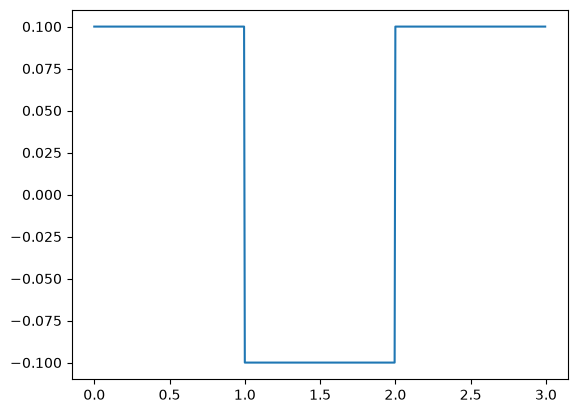

In [ ]:
FREQUENCY = 0.5
def f(t):
  return 0.3*signal.square(2*np.pi*FREQUENCY*t, duty=0.5)
  return 0.1*np.sin(2*np.pi*FREQUENCY*t)

ys = f(ts)

plt.figure()
plt.plot(ts, ys)
plt.show()

In [225]:
import scipy.signal as signal

Ts = 1 / 2000

# Continuous-time plant
plant_s = ([-1.8906], [0.018107, 1, 0])

# Convert to discrete time
plant_z = signal.cont2discrete(plant_s, Ts, method='zoh')

num, den, dt = plant_z

print("Numerator:", num)
print("Denominator:", den)

Numerator: [[ 0.00000000e+00 -1.29322732e-05 -1.28137843e-05]]
Denominator: [ 1.         -1.97276414  0.97276414]


In [226]:
import scipy.signal as signal

# Discrete plant coefficients
NUM = [0.0, -1.29322732e-5, -1.28137843e-5]
DEN = [1.0, -1.97276414, 0.97276414]

# Plant state
plant_state = np.zeros(max(len(NUM), len(DEN)) - 1)

def plant(u):
    global plant_state

    y, plant_state = signal.lfilter(NUM, DEN, [u], zi=plant_state)

    return y[0]

def reset_plant():
    global plant_state
    plant_state = np.zeros(max(len(NUM), len(DEN)) - 1)

In [ ]:
MOTOR_CONTROLLER_FIRST_ORDER_F0 = -1.987525
MOTOR_CONTROLLER_FIRST_ORDER_F1 = 2.012475
MOTOR_CONTROLLER_FIRST_ORDER_G0 = 4.8363
MOTOR_CONTROLLER_FIRST_ORDER_G1 = -4.9717

MOTOR_CONTROLLER_FIRST_ORDER_F0 = -1.875
MOTOR_CONTROLLER_FIRST_ORDER_F1 = 2.125
MOTOR_CONTROLLER_FIRST_ORDER_G0 = 4.227
MOTOR_CONTROLLER_FIRST_ORDER_G1 = -5.581

MOTOR_CONTROLLER_COEF_0 = (MOTOR_CONTROLLER_FIRST_ORDER_F0 / MOTOR_CONTROLLER_FIRST_ORDER_F1)
MOTOR_CONTROLLER_COEF_1 = (MOTOR_CONTROLLER_FIRST_ORDER_G1 / MOTOR_CONTROLLER_FIRST_ORDER_F1)
MOTOR_CONTROLLER_COEF_2 = (MOTOR_CONTROLLER_FIRST_ORDER_G0 / MOTOR_CONTROLLER_FIRST_ORDER_F1)
print(MOTOR_CONTROLLER_COEF_0, MOTOR_CONTROLLER_COEF_1, MOTOR_CONTROLLER_COEF_2)

-0.9876023304637326 -2.470440626591635 2.4031602877054374


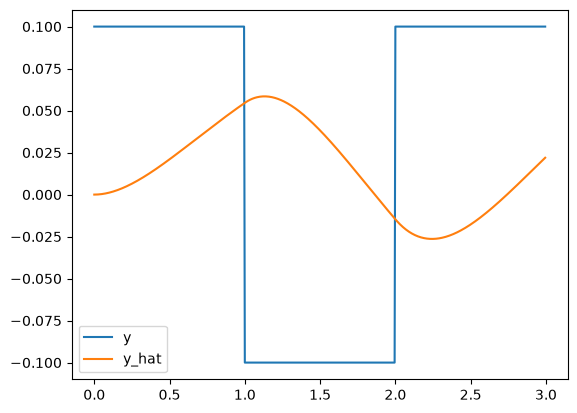

In [228]:
controller_state = 0

def controller(theta_target, theta):
    global controller_state

    err = theta_target - theta

    state = err - MOTOR_CONTROLLER_COEF_0 * controller_state

    u = (
        MOTOR_CONTROLLER_COEF_1 * state
        + MOTOR_CONTROLLER_COEF_2 * controller_state
    )

    controller_state = state

    return u

y_hat = np.zeros_like(ys)
for i, y in enumerate(ys):
    u = controller(y, y_hat[i-1])
    y_hat[i] = plant(u)

plt.figure()
plt.plot(ts, ys, label="y")
plt.plot(ts, y_hat, label="y_hat")
plt.legend()
plt.show()